# Hybrid Manufacturing Production Analysis
**Client:** Operations Manager, Manufacturing Company
**Dataset:** 1,000 historical production jobs (5 machines, 5 operation types)
**Objective:** Identify the drivers of production delays, job failures, and energy inefficiency, and provide management with decision-ready recommendations.

**Client instruction:** Do not assume `Optimization_Category` is automatically correct — validate it against actual performance before using it in any conclusion.

## Phase 1 — Data Loading, Cleaning & Validation

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv('hybrid_manufacturing.csv',
                  parse_dates=['Scheduled_Start', 'Scheduled_End', 'Actual_Start', 'Actual_End'])
df.shape

(1000, 13)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Job_ID                 1000 non-null   str           
 1   Machine_ID             1000 non-null   str           
 2   Operation_Type         1000 non-null   str           
 3   Material_Used          1000 non-null   float64       
 4   Processing_Time        1000 non-null   int64         
 5   Energy_Consumption     1000 non-null   float64       
 6   Machine_Availability   1000 non-null   int64         
 7   Scheduled_Start        1000 non-null   datetime64[us]
 8   Scheduled_End          1000 non-null   datetime64[us]
 9   Actual_Start           871 non-null    datetime64[us]
 10  Actual_End             871 non-null    datetime64[us]
 11  Job_Status             1000 non-null   str           
 12  Optimization_Category  1000 non-null   str           
dtypes: datetime64[u

### 1.1 Missing value check
`Actual_Start` and `Actual_End` have 129 missing values each. Before treating this as a data quality issue, we check whether it aligns with a legitimate business reason.

In [3]:
print(df.isna().sum())
print()
print('Job_Status of rows with missing Actual_Start:')
print(df[df['Actual_Start'].isna()]['Job_Status'].value_counts())

Job_ID                     0
Machine_ID                 0
Operation_Type             0
Material_Used              0
Processing_Time            0
Energy_Consumption         0
Machine_Availability       0
Scheduled_Start            0
Scheduled_End              0
Actual_Start             129
Actual_End               129
Job_Status                 0
Optimization_Category      0
dtype: int64

Job_Status of rows with missing Actual_Start:
Job_Status
Failed    129
Name: count, dtype: int64


**Finding:** All 129 missing `Actual_Start`/`Actual_End` values belong to jobs with `Job_Status = Failed`. This is expected — a failed job never completes execution, so it has no actual start/end timestamp. **This is not missing data to impute; it is a structural characteristic of failed jobs.** We keep these as NaN and exclude them from duration-based calculations.

In [4]:
# Duplicate check
print('Duplicate Job_ID rows:', df['Job_ID'].duplicated().sum())
print('Duplicate full rows:', df.duplicated().sum())

Duplicate Job_ID rows: 0
Duplicate full rows: 0


In [5]:
# Validate Processing_Time against scheduled duration
df['scheduled_duration_min'] = (df['Scheduled_End'] - df['Scheduled_Start']).dt.total_seconds() / 60
match = (df['Processing_Time'] == df['scheduled_duration_min']).sum()
print(f'Processing_Time matches scheduled duration in {match}/{len(df)} rows')

Processing_Time matches scheduled duration in 1000/1000 rows


**Finding:** `Processing_Time` is identical to the scheduled duration (`Scheduled_End - Scheduled_Start`) for all 1,000 rows. It represents *planned* processing time, not actual execution time. We derive actual duration and delay separately below.

In [6]:
# Derive delay metrics
df['actual_duration_min'] = (df['Actual_End'] - df['Actual_Start']).dt.total_seconds() / 60
df['end_delay_min'] = (df['Actual_End'] - df['Scheduled_End']).dt.total_seconds() / 60
df['is_problem'] = df['Job_Status'].isin(['Delayed', 'Failed']).astype(int)

df[['Job_ID', 'Job_Status', 'Processing_Time', 'actual_duration_min', 'end_delay_min']].head()

,Job_ID,Job_Status,Processing_Time,actual_duration_min,end_delay_min
0,J001,Completed,76,76.0,5.0
1,J002,Delayed,79,79.0,10.0
2,J003,Failed,56,NaN,NaN
3,J004,Completed,106,106.0,5.0
4,J005,Completed,46,46.0,2.0


In [7]:
# Range/sanity checks on numeric columns
df[['Material_Used', 'Processing_Time', 'Energy_Consumption', 'Machine_Availability']].describe()

,Material_Used,Processing_Time,Energy_Consumption,Machine_Availability
count,1000.000000,1000.00000,1000.000000,1000.000000
mean,3.026480,71.38400,8.521340,89.163000
std,1.148139,28.48438,3.669941,5.757567
min,1.010000,20.00000,2.010000,80.000000
25%,2.040000,48.00000,5.397500,84.000000
50%,3.080000,72.00000,8.560000,89.000000
75%,4.042500,96.00000,11.672500,94.000000
max,5.000000,120.00000,14.980000,99.000000


No negative values, no impossible ranges (Machine_Availability bounded 80-99%, all durations positive). Dataset is clean — no rows need to be dropped or corrected.

## Phase 2 — Exploratory Data Analysis & Production KPIs

In [8]:
status_summary = df['Job_Status'].value_counts()
status_pct = (status_summary / len(df) * 100).round(1)
kpi_table = pd.DataFrame({'count': status_summary, 'pct': status_pct})
print(kpi_table)

print()
print(f"Total jobs: {len(df)}")
print(f"On-time completion rate: {status_pct['Completed']}%")
print(f"Delay rate: {status_pct['Delayed']}%")
print(f"Failure rate: {status_pct['Failed']}%")
print(f"Overall problem rate (Delayed+Failed): {round(df['is_problem'].mean()*100,1)}%")

            count   pct
Job_Status             
Completed     673  67.3
Delayed       198  19.8
Failed        129  12.9

Total jobs: 1000
On-time completion rate: 67.3%
Delay rate: 19.8%
Failure rate: 12.9%
Overall problem rate (Delayed+Failed): 32.7%


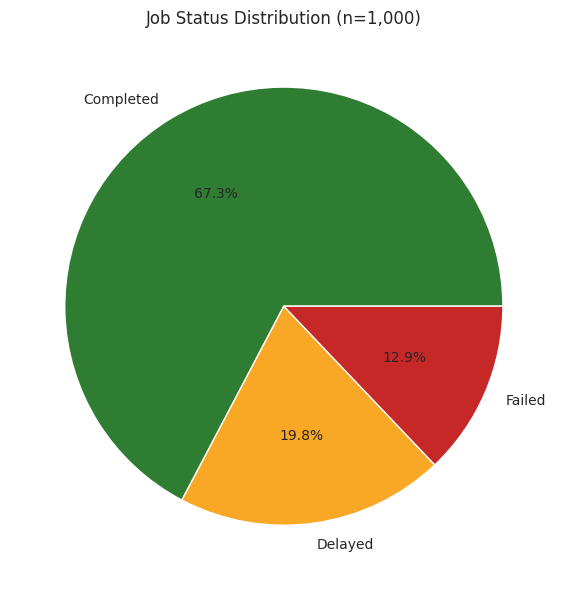

In [9]:
fig, ax = plt.subplots(figsize=(6,6))
colors = ['#2E7D32', '#F9A825', '#C62828']
status_summary.plot(kind='pie', autopct='%1.1f%%', colors=colors, ax=ax, ylabel='')
ax.set_title('Job Status Distribution (n=1,000)')
plt.tight_layout()
plt.savefig('/home/claude/project-10-manufacturing/output/job_status_distribution.png', dpi=150)
plt.show()

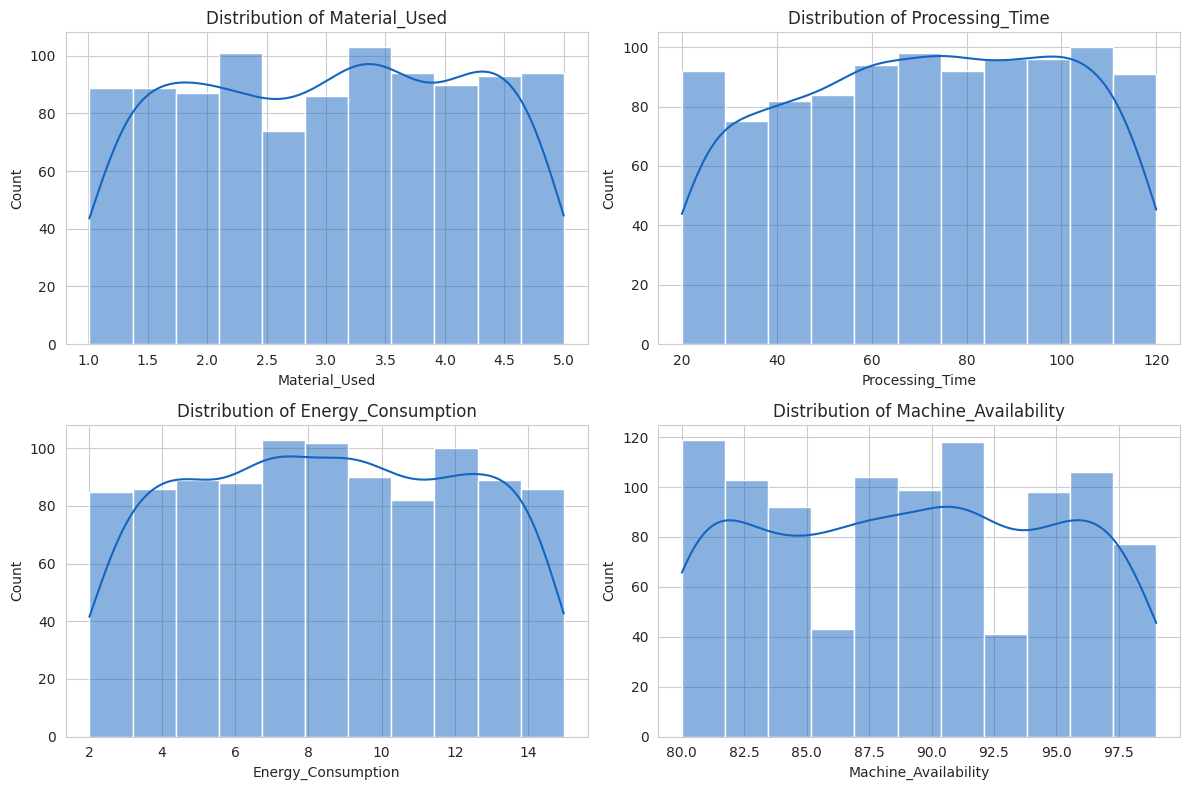

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ['Material_Used', 'Processing_Time', 'Energy_Consumption', 'Machine_Availability']):
    sns.histplot(df[col], kde=True, ax=ax, color='#1565C0')
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.savefig('/home/claude/project-10-manufacturing/output/numeric_distributions.png', dpi=150)
plt.show()

## Phase 3 — Delay & Failure Analysis

In [11]:
delayed = df[df['Job_Status'] == 'Delayed']
print('Delay magnitude (minutes late) — Delayed jobs only:')
print(delayed['end_delay_min'].describe())
print()
print('Completed jobs delay range (should be near zero / within tolerance):')
print(df[df['Job_Status']=='Completed']['end_delay_min'].describe())

Delay magnitude (minutes late) — Delayed jobs only:
count    198.000000
mean      20.146465
std        6.273283
min       10.000000
25%       14.000000
50%       21.000000
75%       26.000000
max       30.000000
Name: end_delay_min, dtype: float64

Completed jobs delay range (should be near zero / within tolerance):
count    673.000000
mean      -0.145617
std        3.138122
min       -5.000000
25%       -3.000000
50%        0.000000
75%        2.000000
max        5.000000
Name: end_delay_min, dtype: float64


**Finding:** `Completed` jobs finish within a tight -5 to +5 minute tolerance of schedule. `Delayed` jobs are 10-30 minutes late (mean ~20 min). There is no ambiguous middle ground — the status labels are cleanly separated by a fixed threshold, not a judgment call.

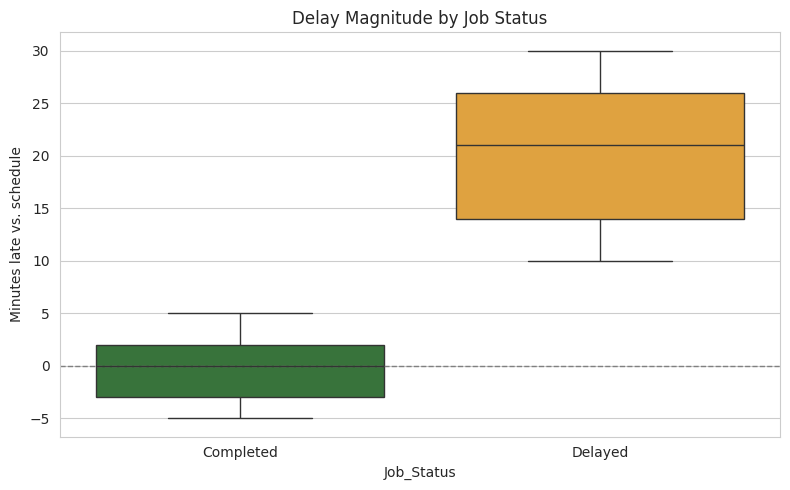

In [12]:
fig, ax = plt.subplots(figsize=(8,5))
sns.boxplot(data=df[df['Job_Status']!='Failed'], x='Job_Status', y='end_delay_min',
            hue='Job_Status', palette={'Completed':'#2E7D32','Delayed':'#F9A825'}, legend=False, ax=ax)
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.set_title('Delay Magnitude by Job Status')
ax.set_ylabel('Minutes late vs. schedule')
plt.tight_layout()
plt.savefig('/home/claude/project-10-manufacturing/output/delay_magnitude_by_status.png', dpi=150)
plt.show()

In [13]:
# Does delay MAGNITUDE (not just occurrence) vary by machine or operation?
f_m, p_m = stats.f_oneway(*[g['end_delay_min'].values for _, g in delayed.groupby('Machine_ID')])
f_o, p_o = stats.f_oneway(*[g['end_delay_min'].values for _, g in delayed.groupby('Operation_Type')])
print(f'Delay magnitude ~ Machine_ID   : F={f_m:.3f}, p={p_m:.4f}')
print(f'Delay magnitude ~ Operation_Type: F={f_o:.3f}, p={p_o:.4f}')

Delay magnitude ~ Machine_ID   : F=0.802, p=0.5252
Delay magnitude ~ Operation_Type: F=0.538, p=0.7077


Neither machine nor operation type explains *how late* a delayed job runs (both p > 0.05). Delay severity appears consistent across the board once a job is delayed at all.

## Phase 4 — Machine Performance Analysis

In [14]:
machine_perf = df.groupby('Machine_ID').agg(
    total_jobs=('Job_ID', 'count'),
    delayed=('Job_Status', lambda x: (x=='Delayed').sum()),
    failed=('Job_Status', lambda x: (x=='Failed').sum()),
    avg_energy=('Energy_Consumption', 'mean'),
    avg_availability=('Machine_Availability', 'mean')
)
machine_perf['problem_rate_pct'] = ((machine_perf['delayed']+machine_perf['failed'])/machine_perf['total_jobs']*100).round(1)
machine_perf = machine_perf.sort_values('problem_rate_pct', ascending=False)
machine_perf

,total_jobs,delayed,failed,avg_energy,avg_availability,problem_rate_pct
Machine_ID,,,,,,
M05,193,48,21,8.455855,89.284974,35.8
M04,199,36,35,8.538492,88.844221,35.7
M03,186,34,29,8.759892,89.419355,33.9
M02,210,43,21,8.423429,89.147619,30.5
M01,212,37,23,8.452547,89.141509,28.3


In [15]:
# Statistical test: is Machine_ID actually associated with Job_Status?
ct = pd.crosstab(df['Machine_ID'], df['Job_Status'])
chi2, p, dof, expected = stats.chi2_contingency(ct)
print(f'Chi-square test — Machine_ID vs Job_Status: chi2={chi2:.3f}, dof={dof}, p-value={p:.4f}')
print()
print('Observed counts:')
print(ct)

Chi-square test — Machine_ID vs Job_Status: chi2=12.091, dof=8, p-value=0.1472

Observed counts:
Job_Status  Completed  Delayed  Failed
Machine_ID                            
M01               152       37      23
M02               146       43      21
M03               123       34      29
M04               128       36      35
M05               124       48      21


**Critical finding:** Although M05 (35.8%) and M04 (35.7%) show the highest raw problem rates versus M01 (28.3%), the chi-square test returns **p = 0.147 — not statistically significant** at the 95% confidence level. With ~200 jobs per machine, a ~7 percentage-point gap is within the range of random variation.

**Business implication:** There is currently no statistical evidence that any single machine is inherently more failure-prone than another. Management should be cautious about singling out M05 for corrective action based on this dataset alone — doing so risks solving a problem that doesn't exist while missing the real cause.

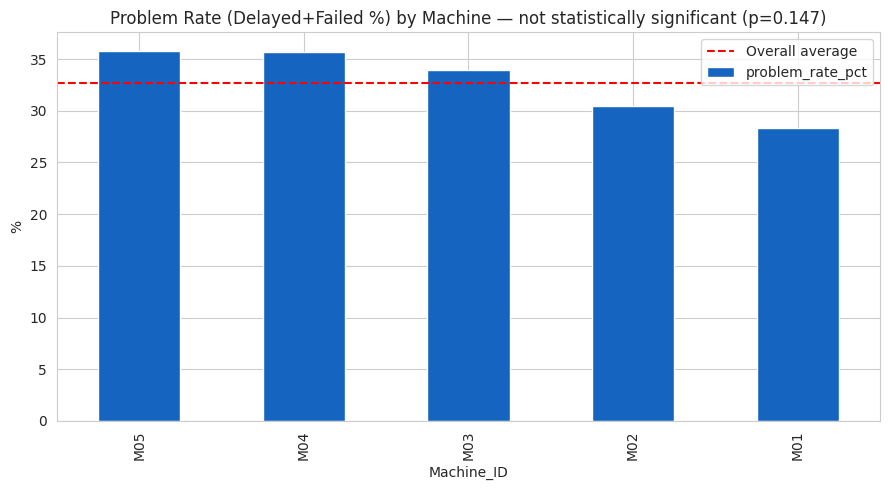

In [16]:
fig, ax = plt.subplots(figsize=(9,5))
machine_perf['problem_rate_pct'].plot(kind='bar', color='#1565C0', ax=ax)
ax.set_title('Problem Rate (Delayed+Failed %) by Machine — not statistically significant (p=0.147)')
ax.set_ylabel('%')
ax.axhline(df['is_problem'].mean()*100, color='red', linestyle='--', label='Overall average')
ax.legend()
plt.tight_layout()
plt.savefig('/home/claude/project-10-manufacturing/output/machine_problem_rate.png', dpi=150)
plt.show()

## Phase 5 — Operation Type Performance Analysis

In [17]:
op_perf = df.groupby('Operation_Type').agg(
    total_jobs=('Job_ID','count'),
    delayed=('Job_Status', lambda x: (x=='Delayed').sum()),
    failed=('Job_Status', lambda x: (x=='Failed').sum()),
    avg_energy=('Energy_Consumption','mean'),
    avg_processing_time=('Processing_Time','mean')
)
op_perf['problem_rate_pct'] = ((op_perf['delayed']+op_perf['failed'])/op_perf['total_jobs']*100).round(1)
op_perf = op_perf.sort_values('problem_rate_pct', ascending=False)
op_perf

,total_jobs,delayed,failed,avg_energy,avg_processing_time,problem_rate_pct
Operation_Type,,,,,,
Lathe,212,44,31,8.478726,71.169811,35.4
Grinding,208,46,25,8.490625,73.365385,34.1
Milling,201,40,27,8.252090,70.208955,33.3
Drilling,189,37,21,8.860741,71.470899,30.7
Additive,190,31,25,8.549737,70.610526,29.5


In [18]:
ct2 = pd.crosstab(df['Operation_Type'], df['Job_Status'])
chi2b, pb, dofb, expb = stats.chi2_contingency(ct2)
print(f'Chi-square test — Operation_Type vs Job_Status: chi2={chi2b:.3f}, p-value={pb:.4f}')

Chi-square test — Operation_Type vs Job_Status: chi2=3.676, p-value=0.8851


Same pattern as machines: p = 0.885, no statistically significant relationship between operation type and delay/failure outcome. Lathe and Grinding show marginally higher raw rates, but this is not distinguishable from noise.

## Phase 6 — Energy Efficiency & Validation of `Optimization_Category`

In [19]:
cross_check = pd.crosstab(df['Job_Status'], df['Optimization_Category'])
cross_check

Optimization_Category,High Efficiency,Low Efficiency,Moderate Efficiency,Optimal Efficiency
Job_Status,,,,
Completed,161,323,183,6
Delayed,0,198,0,0
Failed,0,129,0,0


**Validation finding (this directly addresses the client's warning):**
- Every single `Delayed` job (198) and every single `Failed` job (129) is labeled `Low Efficiency`.
- But `Low Efficiency` *also* contains 323 `Completed` jobs — meaning the label conflates "job didn't finish on time/at all" with "job finished on time but used more energy." These are different problems requiring different fixes.
- `Optimal Efficiency` has only 6 jobs total — too small a sample to generalize from.

**Conclusion: `Optimization_Category` should not be used as a standalone KPI.** It is dominated by job outcome (any non-Completed job is auto-labeled Low Efficiency) rather than being a pure energy-efficiency measure. For genuine efficiency benchmarking we isolate `Completed` jobs only.

In [20]:
completed = df[df['Job_Status']=='Completed'].copy()
completed['energy_per_material'] = completed['Energy_Consumption'] / completed['Material_Used']

eff_summary = completed.groupby('Optimization_Category').agg(
    jobs=('Job_ID','count'),
    avg_energy=('Energy_Consumption','mean'),
    avg_energy_per_material=('energy_per_material','mean'),
    avg_processing_time=('Processing_Time','mean')
).round(2)
eff_summary

,jobs,avg_energy,avg_energy_per_material,avg_processing_time
Optimization_Category,,,,
High Efficiency,161,5.59,2.34,69.35
Low Efficiency,323,8.45,3.32,73.65
Moderate Efficiency,183,11.41,4.32,68.13
Optimal Efficiency,6,2.46,1.04,89.33


In [21]:
groups = [g['Energy_Consumption'].values for _, g in completed.groupby('Optimization_Category')]
f, p = stats.f_oneway(*groups)
print(f'ANOVA — Energy_Consumption ~ Optimization_Category (Completed jobs only): F={f:.2f}, p={p:.2e}')

ANOVA — Energy_Consumption ~ Optimization_Category (Completed jobs only): F=122.10, p=4.52e-63


Among *completed* jobs only, `Optimization_Category` **is** strongly and significantly tied to `Energy_Consumption` (p < 0.0001) — but non-monotonically: `Moderate Efficiency` jobs actually consume *more* energy on average (11.41) than `Low Efficiency` jobs (8.45), which is counter-intuitive for a label implying better performance. This confirms the category's *name* should not be read at face value; it likely reflects a composite scoring rule not fully explained by energy alone.

**Recommendation:** Treat `Optimization_Category` as unreliable for efficiency reporting until its construction logic is clarified with the source system. Use `Energy_Consumption` and `energy_per_material` directly for efficiency tracking instead.

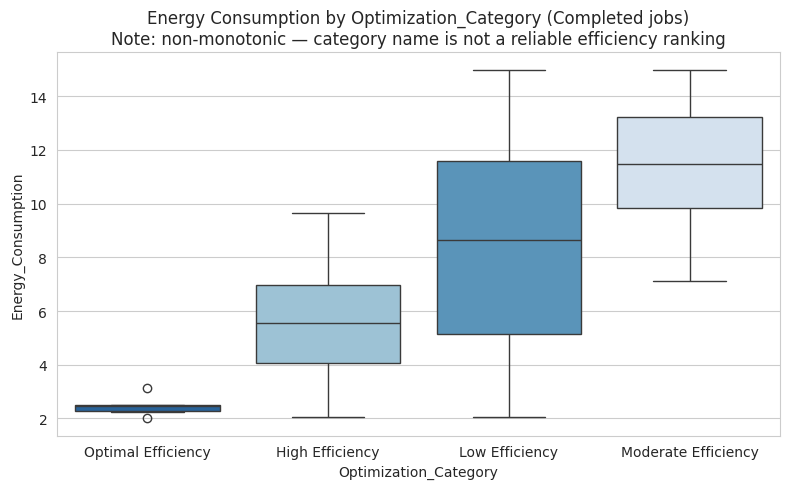

In [22]:
fig, ax = plt.subplots(figsize=(8,5))
order = ['Optimal Efficiency','High Efficiency','Low Efficiency','Moderate Efficiency']
sns.boxplot(data=completed, x='Optimization_Category', y='Energy_Consumption', order=order, ax=ax, hue='Optimization_Category', palette='Blues', legend=False)
ax.set_title('Energy Consumption by Optimization_Category (Completed jobs)\nNote: non-monotonic — category name is not a reliable efficiency ranking')
plt.tight_layout()
plt.savefig('/home/claude/project-10-manufacturing/output/energy_by_category.png', dpi=150)
plt.show()

In [23]:
# Top energy-intensive completed jobs — real candidates for efficiency investigation
top_energy = completed.nlargest(10, 'Energy_Consumption')[['Job_ID','Machine_ID','Operation_Type','Energy_Consumption','Processing_Time','Optimization_Category']]
top_energy

,Job_ID,Machine_ID,Operation_Type,Energy_Consumption,Processing_Time,Optimization_Category
343,J344,M01,Lathe,14.98,94,Moderate Efficiency
980,J981,M02,Drilling,14.98,80,Low Efficiency
262,J263,M04,Lathe,14.87,38,Moderate Efficiency
516,J517,M04,Lathe,14.84,66,Low Efficiency
107,J108,M05,Lathe,14.78,78,Moderate Efficiency
936,J937,M02,Drilling,14.71,103,Low Efficiency
548,J549,M04,Additive,14.70,61,Low Efficiency
274,J275,M03,Additive,14.67,94,Moderate Efficiency
79,J080,M04,Grinding,14.62,82,Low Efficiency
90,J091,M02,Grinding,14.60,60,Low Efficiency


## Phase 7 — Root Cause Investigation

In [24]:
# Test every candidate numeric driver against problem occurrence
print('T-tests: numeric factors vs is_problem (Delayed/Failed = 1, Completed = 0)')
for col in ['Processing_Time','Energy_Consumption','Machine_Availability','Material_Used']:
    g0 = df[df['is_problem']==0][col]
    g1 = df[df['is_problem']==1][col]
    t, p = stats.ttest_ind(g0, g1)
    print(f'  {col:22s}: mean(ok)={g0.mean():.2f}  mean(problem)={g1.mean():.2f}  t={t:.3f}  p={p:.4f}')

T-tests: numeric factors vs is_problem (Delayed/Failed = 1, Completed = 0)
  Processing_Time       : mean(ok)=71.26  mean(problem)=71.64  t=-0.197  p=0.8436
  Energy_Consumption    : mean(ok)=8.52  mean(problem)=8.53  t=-0.051  p=0.9590
  Machine_Availability  : mean(ok)=89.13  mean(problem)=89.24  t=-0.277  p=0.7816
  Material_Used         : mean(ok)=3.02  mean(problem)=3.03  t=-0.087  p=0.9308


In [25]:
# Threshold effect check: does low Machine_Availability specifically predict problems?
df['avail_bin'] = pd.cut(df['Machine_Availability'], bins=[79,85,90,95,100], labels=['80-85','86-90','91-95','96-99'])
avail_rates = (pd.crosstab(df['avail_bin'], df['Job_Status'], normalize='index')*100).round(1)
avail_rates

Job_Status,Completed,Delayed,Failed
avail_bin,,,
80-85,67.2,19.7,13.1
86-90,69.1,17.9,13.0
91-95,65.8,20.6,13.6
96-99,67.2,21.3,11.5


In [26]:
# Time trend check
df['week'] = df['Scheduled_Start'].dt.isocalendar().week
week_rates = df.groupby('week')['is_problem'].agg(problem_rate=('mean'), n=('count'))
week_rates['problem_rate'] = (week_rates['problem_rate']*100).round(1)
week_rates

,problem_rate,n
week,,
11,32.1,240
12,32.9,760


**Root cause conclusion:** None of the measured operational variables — machine identity, operation type, processing time, energy consumption, or machine availability (including at the low end, 80-85%) — show a statistically significant relationship with whether a job is delayed or fails. There is also no meaningful week-over-week trend in the two-week window covered.

This is an important, honest finding rather than a null result to hide: **the current dataset does not capture the actual driver of delays and failures.** Roughly 33% of all jobs (Delayed + Failed combined) are affected, but the cause is not observable in the measured fields. Likely unmeasured factors include operator/shift assignment, upstream material delivery timing, maintenance/breakdown events, or queueing/scheduling conflicts — none of which are present in this dataset.

## Phase 8 — Consolidated Findings Table

In [27]:
findings = pd.DataFrame([
    ['Overall delay rate', '19.8%', '198 of 1,000 jobs finish 10-30 min late'],
    ['Overall failure rate', '12.9%', '129 of 1,000 jobs fail outright (no actual execution recorded)'],
    ['Machine_ID vs outcome', 'p=0.147 (not significant)', 'No machine is statistically more failure-prone'],
    ['Operation_Type vs outcome', 'p=0.885 (not significant)', 'No operation type is statistically more failure-prone'],
    ['Machine_Availability vs outcome', 'p=0.782 (not significant)', 'Even 80-85% availability jobs show no elevated risk'],
    ['Energy_Consumption vs outcome', 'p=0.959 (not significant)', 'Energy use does not predict delay/failure'],
    ['Optimization_Category reliability', 'Confounded with Job_Status', 'All non-Completed jobs default to Low Efficiency; category conflates outcome with energy use'],
    ['Optimization_Category vs Energy (Completed only)', 'p<0.0001, non-monotonic', 'Category name does not track energy consumption in a consistent ranking'],
], columns=['Question','Result','Interpretation'])
findings

,Question,Result,Interpretation
0,Overall delay rate,19.8%,"198 of 1,000 jobs finish 10-30 min late"
1,Overall failure rate,12.9%,"129 of 1,000 jobs fail outright (no actual exe..."
2,Machine_ID vs outcome,p=0.147 (not significant),No machine is statistically more failure-prone
3,Operation_Type vs outcome,p=0.885 (not significant),No operation type is statistically more failur...
4,Machine_Availability vs outcome,p=0.782 (not significant),Even 80-85% availability jobs show no elevated...
5,Energy_Consumption vs outcome,p=0.959 (not significant),Energy use does not predict delay/failure
6,Optimization_Category reliability,Confounded with Job_Status,All non-Completed jobs default to Low Efficien...
7,Optimization_Category vs Energy (Completed only),"p<0.0001, non-monotonic",Category name does not track energy consumptio...
